## [LAB-07] 추론통계

### 03-1_단일표본 T검정

### #01 준비작업

1. 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import my_stats, my_plot
from pandas import DataFrame

# 단일표본 T-Test를 위한 라이브러리
from scipy.stats import ttest_1samp, wilcoxon

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30


### #02 예제(1) - 강아지 체온 변화

1. 데이터 가져오기
- dog_temperature 데이터는 강아지 25마리의 체온을 측정한 데이터이다.
    - 과거의 자료에서 강아지의 평균 체온은 24.3으로 알려져있다.
    - 이번에 조사한 데이터에서도 강아지의 평균 체온이 24.3이라고 해도 좋은지 알고 싶다.

In [2]:
df1 = load_data('dog_temperature')
df1.head()

📚 강아지 25마리의 체온을 측정한 데이터 (출처: 방송통신대학교 통계학개론)


,체온
0,25.800
1,24.600
2,26.100
3,22.900
4,25.100


2. 데이터 분포 시각화

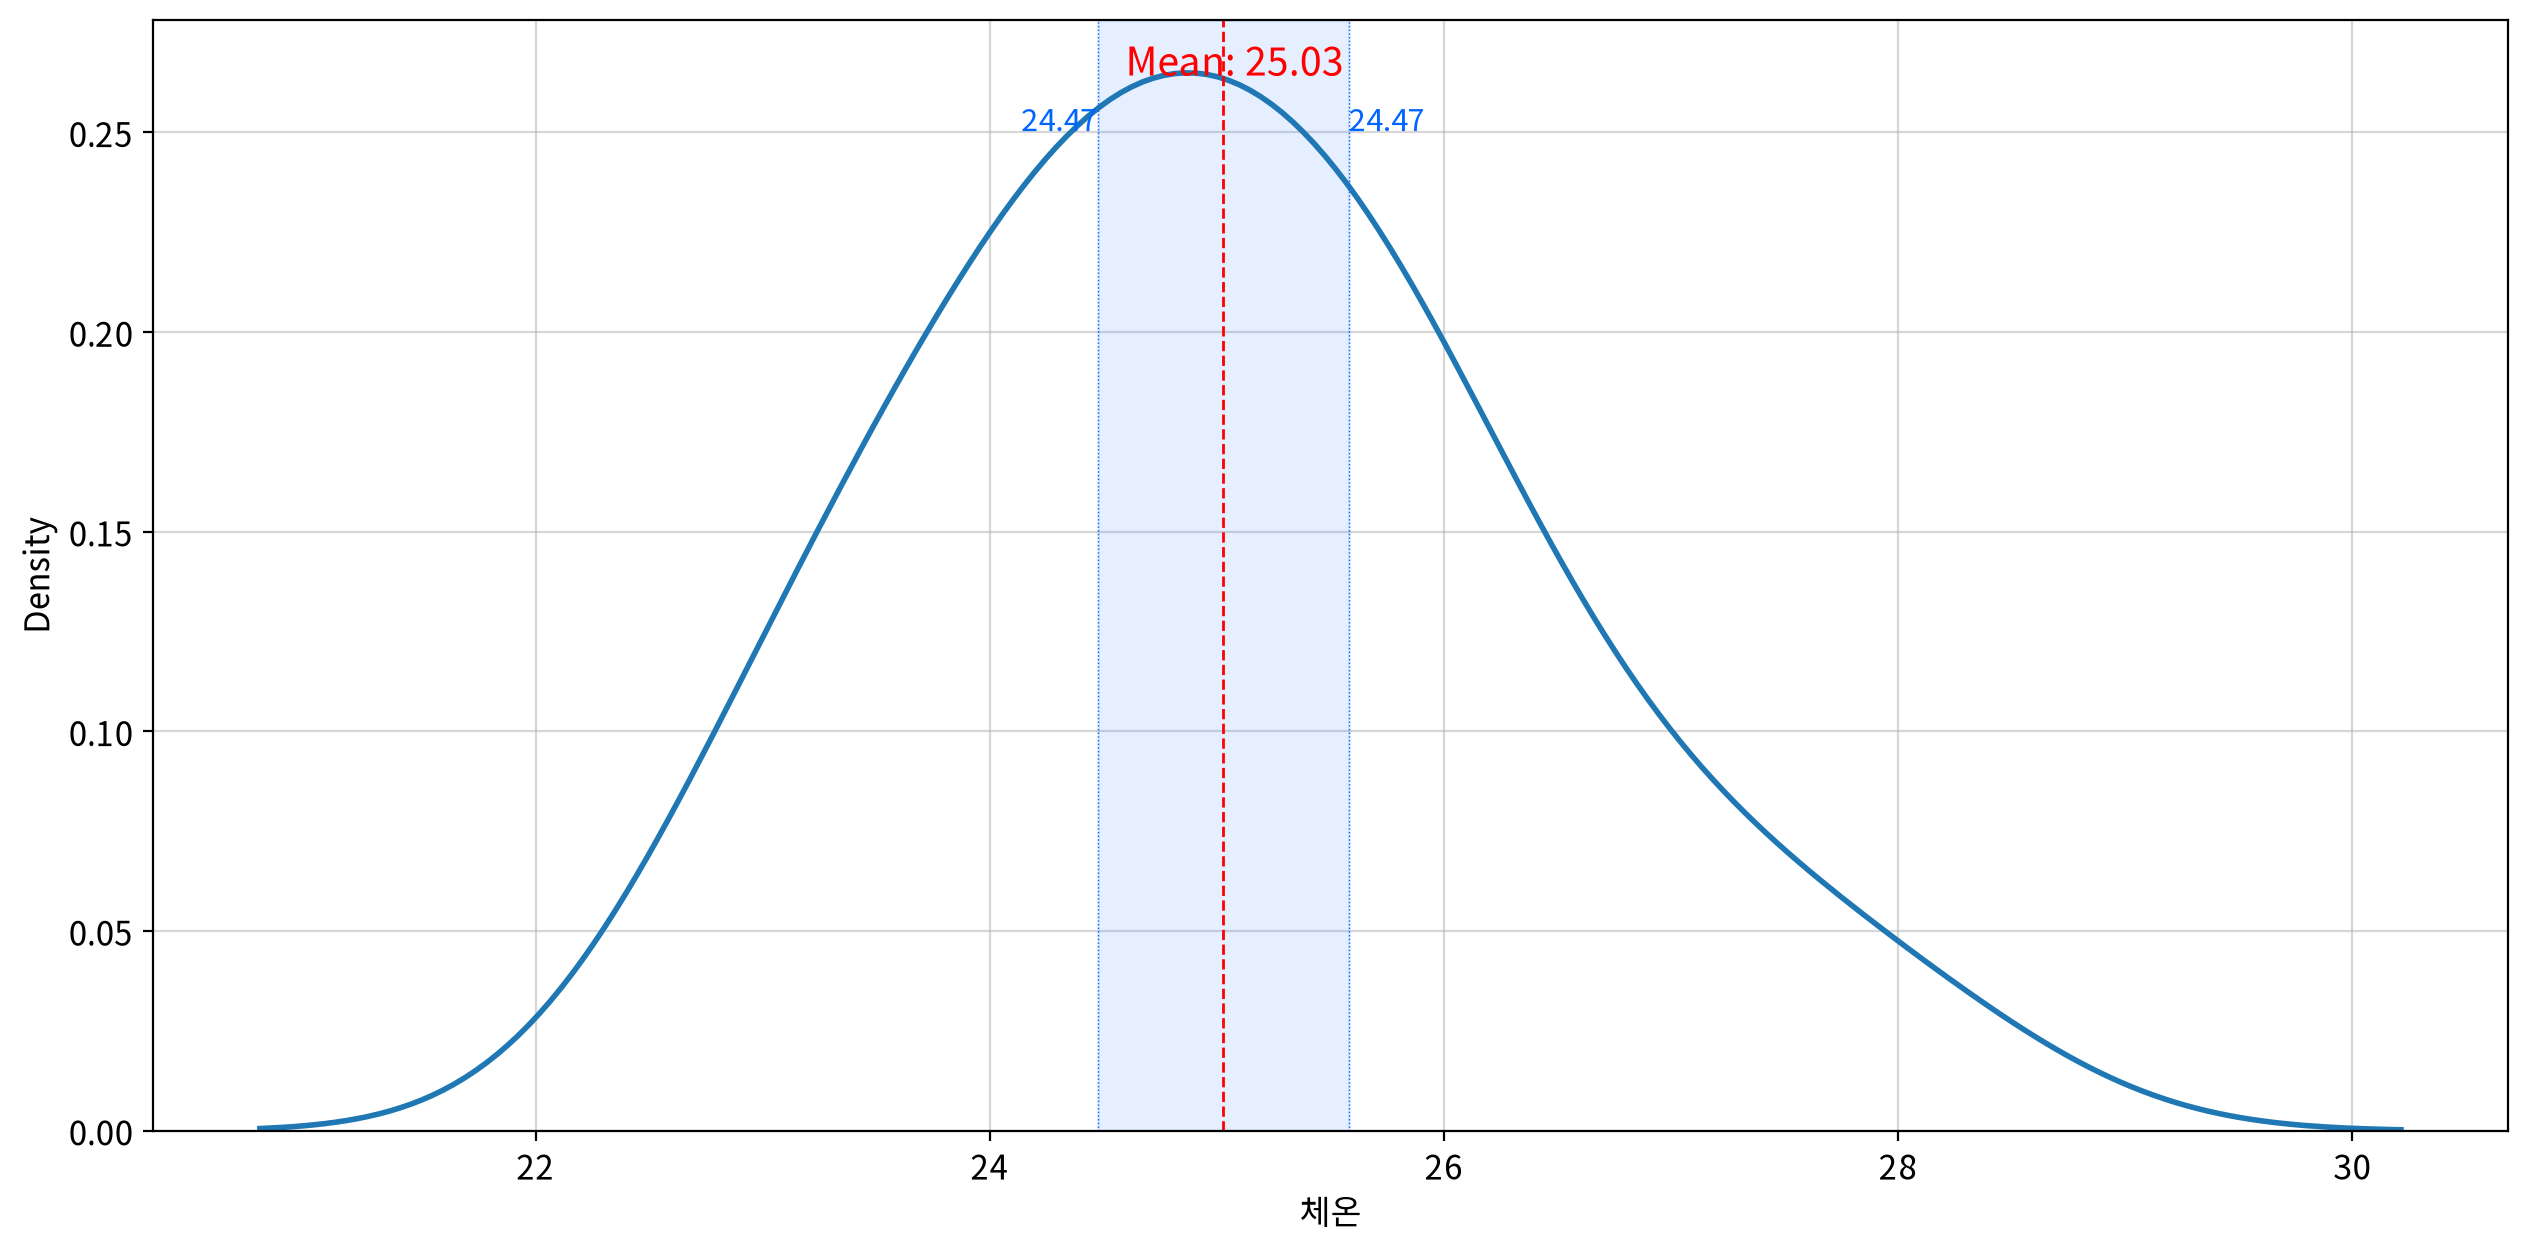

In [3]:
my_plot.kdeplot(df1, x='체온', meanline=True, clevel=0.95)

> 인사이트
> - 커널 밀도 함수 그래프의 모양이 정규분포를 띄고 있으며, 표본평균(25.03)이 신뢰구간(24.5~25.6)에 포함되어 있으므로, 강아지의 체온이 정상범위에 있다고 할 수 있다.
> - 시각화 결과로 정규성 가정을 충족하는 것 같지만 정확한 통계량으로 정규성 충족 여부를 확인하기 위해 NormalTest를 수행한다.

3. 가설검정의 가정 확인
- helpers 패키지의 test_assumption 함수는 NormalTest를 통해 정규성 검정 결과를 반환한다.

In [4]:
my_stats.test_assumptions(df1, columns=['체온'])

,test,statistic,p-value,result
field,,,,
체온,normaltest,0.819,0.664,True


4. One Sample T-Test - 양측검정
- 강아지의 평균 체온이 과거의 자료인 24.3과 달라졌는지 여부
- alternative 파라미터는 two-sided가 기본값이므로 양측검정의 경우 생략 가능

In [5]:
popmean = 24.3              # 비교 기준값을 변수로 저장
alternative = "two-sided"   # 'two-sided', 'less', 'greater'
s, p = ttest_1samp(df1['체온'], popmean, alternative=alternative)
print(f"t-statistic: {s:.4f}, p-value: {p:.4f}")

t-statistic: 2.7128, p-value: 0.0121


> 단일표본 t검정의 결과, t값은 2.713, p-value는 0.012로 나타났다.   
> 따라서 귀무가설을 기각하고 **대립가설을 채택**한다. (p < 0.05)   
> 이는 모집단의 평균(24.3)과 표본 평균 사이에 **유의한 차이가 있음**을 의미한다.

5. One Sample T-Test - 좌측 단측검정
- 강아지의 평균 체온이 과거의 자료인 24.3보다 작아졌는지 알고자 하는 경우
    - alternative 파라미터에 less를 설정한다.

In [6]:
popmean = 24.3              # 비교 기준값을 변수로 저장
alternative = "less"   # 'two-sided', 'less', 'greater'
s, p = ttest_1samp(df1['체온'], popmean, alternative=alternative)
print(f"t-statistic: {s:.4f}, p-value: {p:.4f}")

t-statistic: 2.7128, p-value: 0.9939


> 단일표본 t검정(alternative = "less") 결과, t값은 2.713, p-value는 0.994로 나타났다.   
> p-value가 0.05보다 크므로 **귀무가설을 기각할 수 없다**. (p > 0.05)   
> 즉, 강아지의 평균 체온은 24.3보다 작지 않다.

5. One Sample T-Test - 우측 단측검정
- 강아지의 평균 체온이 과거의 자료인 24.3보다 커졌는지 알고자 하는 경우
    - alternative 파라미터에 greater를 설정한다.

In [7]:
popmean = 24.3              # 비교 기준값을 변수로 저장
alternative = "greater"   # 'two-sided', 'less', 'greater'
s, p = ttest_1samp(df1['체온'], popmean, alternative=alternative)
print(f"t-statistic: {s:.4f}, p-value: {p:.4f}")

t-statistic: 2.7128, p-value: 0.0061


> 단일표본 t검정(alternative = "greater") 결과, t값은 2.713, p-value는 0.006로 나타났다.   
> p-value가 0.05보다 작으므로 **귀무가설을 기각하고 대립가설을 채택한다**. (p < 0.05)   
> 즉, 강아지의 평균 체온은 24.3보다 크다.

### #03 예제(2) - 생명보험 가입 금액 평균 비교

1. 데이터 가져오기
- insur 데이터는 어느 보험회사에서 한 해 동안 모집한 가입원들에 대한 가입 정보이다.   
    - 이 회사에서 올해 실적을 가입원들의 평균 가입금액이 1억원인 것을 목표로 삼았을 때,   
      이 회사는 목표실적을 달성했다고 볼 수 있는지 검정하라.

In [8]:
df2 = load_data('insur')
df2.head()

📚 어느 보험회사에서 한해 동안 모집한 가입원들에 대한 가입 정보 (출처: 방송통신대학교 통계학개론)

    field     description
--  --------  ------------------------------------------------------
 0  직업      1=육체노동, 2=정신노동(직상인), 3=자영업
 1  교육수준  1=초등학교 이하, 2=중졸 및 고졸, 3=대졸, 4=대학원 졸업
 2  성별      1=남자, 2=여자
 3  나이      숫자
 4  가입금액  단위=천만원
 5  월수입    단위=만원



,직업,교육수준,성별,나이,가입금액,월수입
0,1,2,1,35,15.000,100
1,2,3,1,40,10.000,150
2,2,3,2,36,8.000,120
3,3,4,2,38,12.000,140
4,1,1,1,45,10.000,150


2. 데이터 분포 시각화

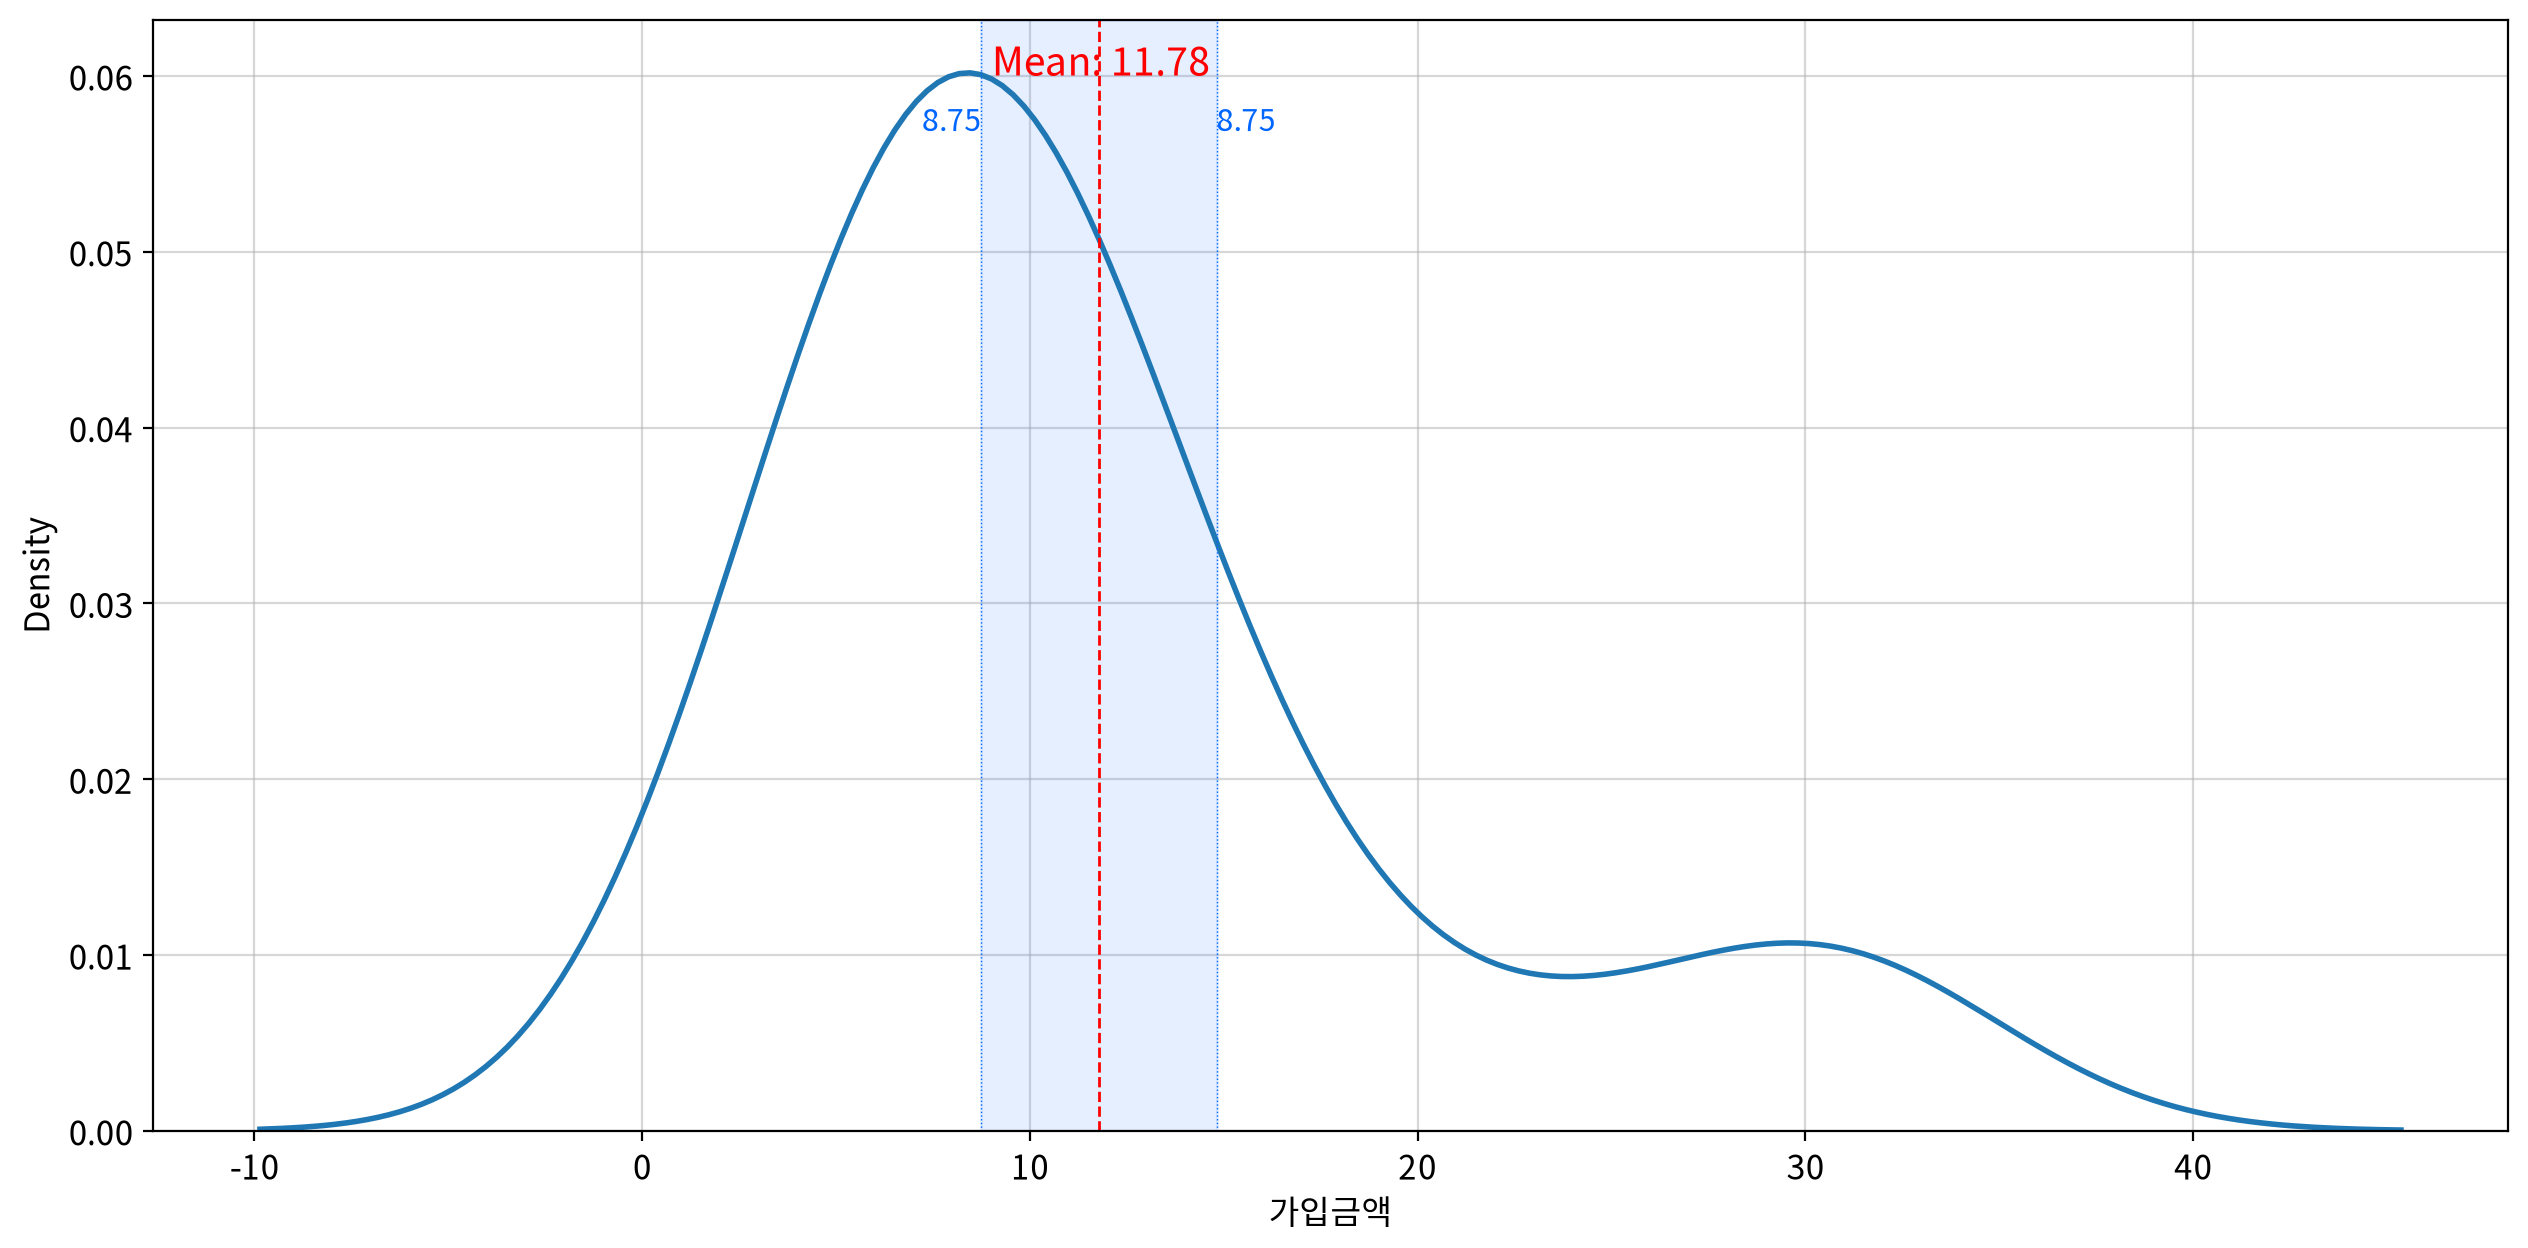

In [9]:
my_plot.kdeplot(df2, x='가입금액', meanline=True, clevel=0.95)

> 인사이트
> - 표본평균(11.8)이 신뢰구간(8.7~14.8)에 포함되어 있으므로 가입금액의 데이터는 정상범위에 있다고 할 수 있지만, 커널 밀도 함수 그래프의 모양을 보았을 때 정규분포를 만족하지는 않고 있다.

3. 데이터의 정규성 검정

In [10]:
my_stats.test_assumptions(df2, columns='가입금액')

,test,statistic,p-value,result
field,,,,
가입금액,normaltest,11.438,0.003,False


> 주어진 데이터는 p-value가 0.003이므로 정규성을 충족하지는 않는다. (p < 0.05)   
> One Sample T-Test를 사용하지 않고 Wilcoxon Signed Rank Test를 수행해야 한다.

4. Wilcoxon Signed Rank Test - 양측검정
- 가입금액의 평균이 1억원과 같은지, 다른지 여부

In [11]:
# 천만원 단위에서 1억원
target_value = 10.0

# 기준값을 뺀 차이에 대한 Wilcoxon 부호순위 검정
s, p = wilcoxon(df2['가입금액'] - target_value)
print(f"Wilcoxon statistic: {s:.4f}, p-value: {p:.4f}")

Wilcoxon statistic: 183.5000, p-value: 0.8948


> Wilcoxon Signed Rank Test 결과 보험 가입금액의 모평균이 1억원이라는 귀무가설을 기각할 수 없다. (p >= 0.05)   
> 즉, 보험 가입금액의 평균은 1억원이다.

4. Wilcoxon Signed Rank Test - 좌측 단측검정
- 가입금액의 평균이 1억원보다 작은지 여부

In [12]:
s, p = wilcoxon(df2['가입금액'] - target_value, alternative='less')
print(f"Wilcoxon statistic: {s:.4f}, p-value: {p:.4f}")

Wilcoxon statistic: 194.5000, p-value: 0.5526


> Wilcoxon Signed Rank Test 결과 보험 가입금액의 모평균이 1억원보다 작지 않다는 귀무가설을 기각할 수 없다. (p >= 0.05)

5. Wilcoxon Signed Rank Test - 우측 단측검정
- 가입금액의 평균이 1억원보다 큰지 여부

In [13]:
s, p = wilcoxon(df2['가입금액'] - target_value, alternative='greater')
print(f"Wilcoxon statistic: {s:.4f}, p-value: {p:.4f}")

Wilcoxon statistic: 194.5000, p-value: 0.4474


> Wilcoxon Signed Rank Test 결과 보험 가입금액의 모평균이 1억원보다 크지 않다는 귀무가설을 기각할 수 없다. (p >= 0.05)

### #04 모듈 기능 확인

1. 강아지 체온 변화

In [14]:
my_stats.test_1sample(df1, column='체온', popmean=24.3)

statistic  p-value  significant    result
test              alternative                                           
One-sample t-test two-sided        2.713    0.012         True  μ ≠ 24.3
                  less             2.713    0.994        False  μ ≥ 24.3
                  greater          2.713    0.006         True  μ > 24.3

2. 생명보험 가입 평균 금액 비교

In [15]:
my_stats.test_1sample(df2, column='가입금액', popmean=10)

statistic  p-value  significant  result
test                      alternative                                         
Wilcoxon signed-rank test two-sided      183.500    0.895        False  μ = 10
                          less           194.500    0.553        False  μ ≥ 10
                          greater        194.500    0.447        False  μ ≤ 10

---

## 연습문제
### 빵집의 양심

이 초코빵의 무게는 500g이라고 표시되어 있다.   
하지만 당신은 자신이 구매하는 빵이 500g이 맞는지 의구심이 들기 시작한다.   
그래서 1개월간 초코빵을 사온 뒤 매일 무게를 기록하였고 그 결과는 bread 데이터셋으로 저장하였다.   
25일간 측정한 빵의 평균 무게는 480g이었다.   
이 값을 가지고 초코빵의 무게가 500g이 되지 않는다며 베이커리를 찾아가 컴플레인을 해야 할까?

In [16]:
# 라이브러리 참조
from jussam import load_data
from helpers import my_stats

In [17]:
# 데이터 불러오기
origin = load_data('bread')
origin.head()

📚 매일 아침 동네 빵집에서 식빵을 구입해 무게를 기록한 데이터


,무게
0,482
1,479
2,485
3,474
4,479


#### 빵의 평균 무게가 500g과 다른지 확인

| 구분               | 수식            | 내용                                       |
| ------------------ | --------------- | ------------------------------------------ |
| 빵의 평균 무게     | $\mu$           |                                            |
| 귀무가설($H_0$)    | $\mu = 500$     | 빵의 평균 무게가 `500`과 차이가 없다.      |
| 대립가설($H_1$)    | $\mu \neq 500$  | 빵의 평균 무게가 `500`과 차이가 있다.      |

In [18]:
my_stats.test_1sample(origin, column='무게', popmean=500)

statistic  p-value  significant   result
test              alternative                                          
One-sample t-test two-sided      -37.524    0.000         True  μ ≠ 500
                  less           -37.524    0.000         True  μ < 500
                  greater        -37.524    1.000        False  μ ≤ 500

25일간 측정한 평균 무게 `480g`은 단순한 우연(측정 오차)으로 보기 어렵다. 단일표본 T검정 결과 p-value가 `0.05`보다 훨씬 작아(`< 0.001`) 빵의 평균 무게가 표시값 `500g`보다 통계적으로 유의하게 **가볍다**는 것이 확인되었다. 따라서 베이커리를 찾아가 컴플레인을 제기할 **충분한 통계적 근거가 있다.**